# Uji Data Pipeline — Anggota 2

Bukti preprocessing Flickr8k sesuai kontrak `README.md`. Notebook ini dapat dijalankan di Windows lokal maupun Google Colab dan tidak melakukan training atau ekstraksi fitur CNN.

Untuk lokal, jalankan Jupyter dari root repo atau atur environment variable `IMAGE_CAPTIONING_ROOT` ke lokasi repo.

## 1. Setup repo dan Google Drive

In [1]:
from pathlib import Path
import os
import sys

# Path lokal tetap untuk project ini.
IN_COLAB = False
REPO_ROOT = Path(r'D:\Lecture\Generative AI\Image Captioning')
ARCHIVE_PATH = REPO_ROOT / 'archive.zip'
DATA_DIR = REPO_ROOT / 'data'

if not REPO_ROOT.is_dir():
    raise FileNotFoundError(f'Root repo tidak ditemukan: {REPO_ROOT}')
if not ARCHIVE_PATH.is_file():
    raise FileNotFoundError(f'archive.zip tidak ditemukan: {ARCHIVE_PATH}')

os.chdir(REPO_ROOT)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
print('Mode: Lokal Antigravity')
print('Repo:', REPO_ROOT)
print('Archive:', ARCHIVE_PATH)

Mode: Lokal
Repo: D:\Lecture\Generative AI\Image Captioning


## 2. Ekstrak `archive.zip` bila dataset belum tersedia

In [2]:
import zipfile

IMAGES_DIR = DATA_DIR / 'Images'
CAPTIONS_FILE = DATA_DIR / 'captions.txt'

if not (IMAGES_DIR.is_dir() and CAPTIONS_FILE.is_file()):
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    target_root = DATA_DIR.resolve()
    with zipfile.ZipFile(ARCHIVE_PATH) as archive:
        for member in archive.infolist():
            destination = (DATA_DIR / member.filename).resolve()
            if destination != target_root and target_root not in destination.parents:
                raise ValueError(f'Path ZIP tidak aman: {member.filename}')
        archive.extractall(DATA_DIR)
    print('Ekstraksi selesai dari:', ARCHIVE_PATH)
else:
    print('Dataset sudah tersedia; ekstraksi dilewati.')

print('Images:', IMAGES_DIR)
print('Captions:', CAPTIONS_FILE)

Dataset sudah tersedia; ekstraksi dilewati.
Images: D:\Lecture\Generative AI\Image Captioning\data\Images
Captions: D:\Lecture\Generative AI\Image Captioning\data\captions.txt


## 3. Bangun split, vocabulary, dataset, dan DataLoader

In [3]:
from src.dataset import create_data_pipeline
from src.vocab import END_IDX, PAD_IDX, START_IDX, UNK_IDX

pipeline = create_data_pipeline(
    IMAGES_DIR,
    CAPTIONS_FILE,
    batch_size=64,
    min_freq=5,
    seed=42,
    val_size=1000,
    test_size=1000,
    num_workers=2 if IN_COLAB else 0,
    pin_memory=IN_COLAB,
)

def caption_count(names):
    return sum(len(pipeline.captions_by_image[name]) for name in names)

print(f'Train: {len(pipeline.splits.train):,} gambar, {caption_count(pipeline.splits.train):,} caption')
print(f'Val  : {len(pipeline.splits.val):,} gambar, {caption_count(pipeline.splits.val):,} caption')
print(f'Test : {len(pipeline.splits.test):,} gambar, {caption_count(pipeline.splits.test):,} caption')
print(f'Vocabulary: {len(pipeline.vocab):,} token')
print({'<pad>': PAD_IDX, '<start>': START_IDX, '<end>': END_IDX, '<unk>': UNK_IDX})

Train: 6,091 gambar, 30,455 caption
Val  : 1,000 gambar, 5,000 caption
Test : 1,000 gambar, 5,000 caption
Vocabulary: 2,579 token
{'<pad>': 0, '<start>': 1, '<end>': 2, '<unk>': 3}


## 4. Tampilkan contoh transform, encoding, dan decoding

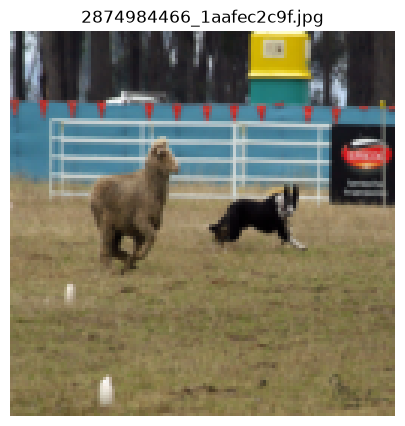

Caption asli : A black and white dog is playing with a sheep in a field .
Tensor       : [1, 11, 228, 53, 2527, 644, 1128, 1646, 2545, 11, 1926, 1102, 11, 789, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Hasil decode : a black and white dog is playing with a sheep in a field


In [4]:
import matplotlib.pyplot as plt

image_tensor, caption_tensor = pipeline.val_dataset[0]
image_name, raw_caption = pipeline.val_dataset.samples[0]
display_image = (image_tensor * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0)

plt.figure(figsize=(5, 5))
plt.imshow(display_image)
plt.axis('off')
plt.title(image_name)
plt.show()

print('Caption asli :', raw_caption)
print('Tensor       :', caption_tensor.tolist())
print('Hasil decode :', pipeline.vocab.decode(caption_tensor.tolist()))

## 5. Verifikasi satu batch dan kontrak akhir

In [5]:
import torch

images, captions = next(iter(pipeline.train_loader))
print('Image batch  :', tuple(images.shape), images.dtype)
print('Image min/max:', images.min().item(), images.max().item())
print('Caption batch:', tuple(captions.shape), captions.dtype)
print('Panjang caption:', captions.shape[1])

train, val, test = map(set, (
    pipeline.splits.train, pipeline.splits.val, pipeline.splits.test
))
assert len(pipeline.captions_by_image) == 8091
assert (len(train), len(val), len(test)) == (6091, 1000, 1000)
assert train.isdisjoint(val) and train.isdisjoint(test) and val.isdisjoint(test)
assert [PAD_IDX, START_IDX, END_IDX, UNK_IDX] == [0, 1, 2, 3]
assert images.shape[1:] == (3, 128, 128)
assert images.dtype == torch.float32 and torch.isfinite(images).all()
assert images.min() >= -1 and images.max() <= 1
assert captions.shape[1] == 30 and captions.dtype == torch.int64
print('LULUS: seluruh kontrak preprocessing terpenuhi.')

Image batch  : (64, 3, 128, 128) torch.float32
Image min/max: -1.0 1.0
Caption batch: (64, 30) torch.int64
Panjang caption: 30
LULUS: seluruh kontrak preprocessing terpenuhi.
